# 04 · The decision problem

Here I turn "should I buy now or wait?" into a precise problem: what the
traveler knows each day, what a strategy is, and how a strategy is scored.

**Key takeaways**
1. Buying a ticket is an **optimal stopping problem**. Each day I see
   today's fare and either buy or wait, using only what I know so far.
2. I score every strategy by **savings vs. buying on the first day**, in
   dollars and in percent, plus how often waiting **cost** money.
3. Every model has to beat simple rules: **buy now**, **buy N days out**,
   and the **hindsight best**, which is an upper bound no real strategy can
   reach.
4. In theory, the best strategy has a simple shape: **buy as soon as the
   fare drops below a threshold**, and that threshold rises as departure
   gets closer.
5. Even with perfect hindsight, a traveler starting 60 days out could save
   about 30% ($53) on average, and from 14 days out only about 8%. That
   caps what any strategy can achieve.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flight_pricing.backtest import (START_DAYS, buy_day, fixed_day_rule, hindsight_best,
                                     load_fare_matrix, price_paid, score)
from flight_pricing.data import connect
from flight_pricing.plotting import SERIES, TEXT_MUTED, use_style

use_style()
con = connect()
trips, F = load_fare_matrix(con)
print(f"{len(trips):,} trips, each with up to 60 days of cheapest fares")

26,677 trips, each with up to 60 days of cheapest fares


## The setup

I'm planning one **trip** (a route on a flight date) and start looking
$s$ days before departure. Each day $t = s, s-1, \dots, 1$ I see $P_t$,
the cheapest fare $t$ days out, and choose:

- **buy** at $P_t$ and stop, or
- **wait** until tomorrow.

If I haven't bought by the last day, I have to buy then. On a day with no
price in the data, I can't buy and just keep waiting.

I test five starting points, $s \in \{60, 45, 30, 21, 14\}$, because a
traveler two months out faces a different problem from one two weeks out.

## What a strategy is

A strategy decides, on each day, whether to buy, **using only what I know
that day**: today's fare, the fares I've already seen, the route, the date.
Never tomorrow's fare.

Mathematically, the day I buy, $\tau$, is a **stopping time**: whether
$\tau = t$ can depend only on information available at time $t$. That one
rule is the line between a real strategy and cheating with hindsight, and
my backtest enforces it.

## What kind of problem is this?

Three names apply, each one a special case of the one before it:

| Level | What it means here |
|---|---|
| **Stochastic optimization** | Minimize the expected price paid, $\mathbb{E}[P_\tau]$, when future fares are random |
| **Markov decision process (MDP)** | Decide repeatedly over time: each day I'm in a state (today's fare and what I know), take an action, and the state changes randomly. The horizon is finite (at most 60 days). |
| **Optimal stopping** | The MDP has only two actions, buy (stop) or wait (continue), and buying ends the problem |

The textbook version is the "asset selling problem" (Bertsekas, *Dynamic
Programming and Optimal Control*). Mine is the buying version: I can't go
back to yesterday's price, and there's a hard deadline. It's also the same
math as deciding when to exercise an American option.

**Two things make this version special:**

1. **My action doesn't affect prices.** One traveler buying a ticket doesn't
   move the fare, so the price path is the same whether I buy or wait. That
   means any strategy can be replayed **exactly** on historical data. In most
   reinforcement-learning problems (robots, games), actions change what
   happens next, and judging a new strategy from old data is much harder.
2. **Strictly, it's only partly observable.** The true state includes things
   I can't see, like seats left in each fare class and the airline's pricing
   rules. I approximate that hidden state with what I can see: today's fare
   vs. the route's usual fare, recent moves, the cheapest fare so far, and
   days to departure.

**How the later notebooks attack it:**

| Notebook | Approach | In MDP terms |
|---|---|---|
| 05 | Fixed rules ("buy N days out") | Policies that ignore the state |
| 06 | Predict a fare drop, wait above a cutoff | A heuristic that looks only a few weeks ahead |
| 07 | Solve the Bellman equation on a fitted price model | Model-based dynamic programming |
| 08 | Learn the value of waiting from past price paths | Model-free (offline) reinforcement learning |

## How I score a strategy

Compared with buying immediately at $P_s$, a strategy that buys at $P_\tau$
saves

$$S = P_s - P_\tau \qquad \text{(negative means waiting cost me money)}$$

Across many trips $i = 1, \dots, n$ I report:

| Metric | Formula | Question it answers |
|---|---|---|
| Average $ saved | $\frac{1}{n}\sum_i S_i$ | How many dollars per trip? |
| Average % saved | $\frac{1}{n}\sum_i \frac{S_i}{P_{s,i}}$ | How much better off is a typical trip? (every trip counts equally) |
| Total % saved | $\frac{\sum_i S_i}{\sum_i P_{s,i}}$ | What share of my total spend did I save? (expensive trips count more) |
| Share lost money | $\frac{1}{n}\#\{i : S_i < 0\}$ | How often did waiting backfire? |

I use both percentages because $30 off a $200 fare (15%) is a much bigger
win than $30 off $1,000 (3%), and the two averages can disagree.

## The simple rules every model must beat

- **Buy now:** $\tau = s$. Saves exactly $0, so it's the baseline.
- **Buy N days out:** wait until $N$ days before departure, whatever the
  price. No model needed. Notebook 02 suggests $N \approx 21$.
- **Hindsight best:** buy on the cheapest day, $P_\tau = \min_{t \le s} P_t$.
  This needs the future, so it isn't a real strategy. It's the **upper
  bound** on what any strategy could save.

### One real trip

A JFK → LAX trip, starting 30 days out:

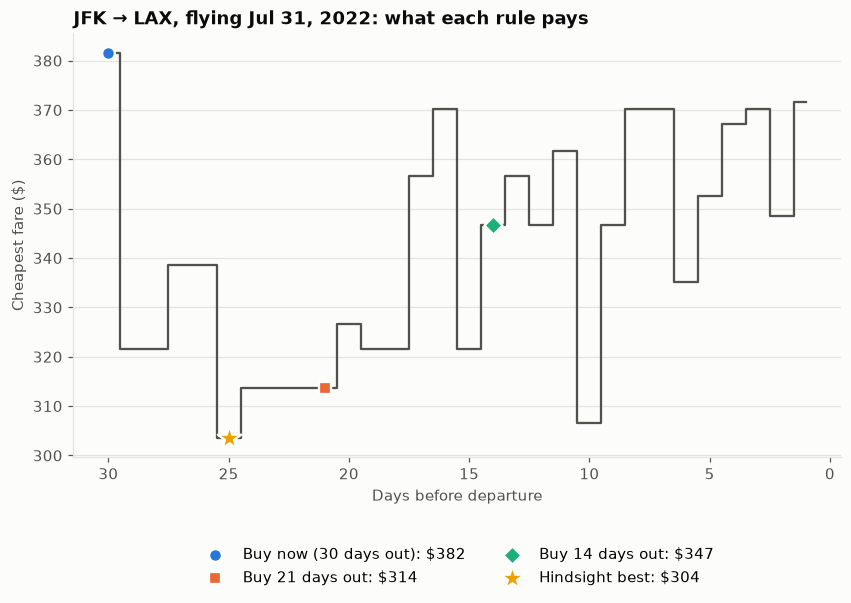

In [2]:
key = trips.reset_index()
s0 = 30
cand = key[(key.origin == "JFK") & (key.dest == "LAX")
           & np.all(~np.isnan(F[key.index, 1:s0 + 1]), axis=1)].copy()
cand["gap"] = F[cand.index, s0] - hindsight_best(F[cand.index], s0)
ex = cand[cand.gap > 0].sort_values("gap").iloc[len(cand[cand.gap > 0]) // 2]
path = F[ex.name, 1:s0 + 1]
days = np.arange(1, s0 + 1)

rules = {
    "Buy now (30 days out)": s0,
    "Buy 21 days out": 21,
    "Buy 14 days out": 14,
    "Hindsight best": int(days[np.argmin(path)]),
}

fig, ax = plt.subplots(figsize=(9, 5))
ax.step(days, path, where="mid", color=TEXT_MUTED, linewidth=1.5)
for (label, d), color, marker in zip(rules.items(), SERIES, ["o", "s", "D", "*"]):
    ax.scatter(d, F[ex.name, d], s=260 if marker == "*" else 70, color=color, marker=marker,
               zorder=3, edgecolor="white", linewidth=1.5, label=f"{label}: ${F[ex.name, d]:,.0f}")
ax.set_title(f"JFK → LAX, flying {ex.flightDate:%b %d, %Y}: what each rule pays")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Cheapest fare ($)")
ax.invert_xaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.show()

Each marker is where a rule would have bought. Buying immediately cost $382.
Waiting until 21 days out got $314, close to the best fare of the whole
month ($304), but waiting until 14 days out was already too late. The hindsight best (star) is
only knowable after the fact. The gap between it and the other markers is
the money a smarter strategy could try to capture.

## The theory: the best strategy is a threshold

Before fitting any model, it helps to know what the *ideal* strategy looks
like. Let $V_t(p)$ be the **expected price I'll end up paying** if today's
fare is $p$, there are $t$ days left, and I act optimally from here on.

On the last day I must buy: $V_1(p) = p$. On any earlier day I compare
buying now with the expected cost of waiting:

$$V_t(p) = \min\big\{\, p,\; C_t(p) \,\big\}, \qquad
C_t(p) = \mathbb{E}\big[\,V_{t-1}(P_{t-1}) \mid P_t = p\,\big]$$

This is the **Bellman equation**. $C_t(p)$ is the *continuation value*,
the expected cost of waiting one more day and then acting optimally.
**Buy when $p \le C_t(p)$.**

**Claim:** the optimal rule is "buy if $P_t \le b_t$" for a threshold
$b_t$.

**Proof when tomorrow's fare doesn't depend on today's.** Then
$C_t(p) = c_t$ is just a number, so the rule is "buy if $p \le c_t$", a
threshold with $b_t = c_t$. The thresholds follow from working backward
from departure:

$$c_2 = \mathbb{E}[P_1], \qquad c_{t+1} = \mathbb{E}\big[\min(P_t,\, c_t)\big]$$

Since $\min(P_t, c_t) \le c_t$ always, $c_{t+1} \le c_t$. So **the
threshold rises as departure gets closer**: with fewer days left, there are
fewer chances for a better price, so I should accept a higher one. This
holds whatever the fare distributions are on each day. $\blacksquare$

**When today's fare does matter** (prices are a Markov chain): the rule is
still a threshold as long as $C_t(p)$ rises *more slowly* than $p$, meaning
a fare that's $1 higher today raises my expected future cost by less than
$1. That's when part of a price jump tends to reverse. Then
$p - C_t(p)$ is increasing, so the set of prices where I buy is everything
below a cutoff. Notebook 07 estimates the Markov chain from the data and
checks the threshold shape numerically.

*Interview version:* "Buying a ticket is an optimal stopping problem. From
the Bellman equation, the optimal policy is a reservation-price rule: buy
once the fare drops below a threshold that rises as departure approaches,
because the option value of waiting shrinks."

## How much is there to gain at all?

The hindsight best shows the most any strategy could save from each
starting point:

In [3]:
rows = []
for s in START_DAYS:
    start_fare = F[:, s]
    rows.append(score(start_fare, hindsight_best(F, s)).rename(f"{s} days out"))
upper = pd.DataFrame(rows)
upper[["trips", "avg_saved_usd", "avg_saved_pct", "total_saved_pct", "share_saved_money"]].round(3)

,trips,avg_saved_usd,avg_saved_pct,total_saved_pct,share_saved_money
60 days out,15333.0,52.830,0.305,0.337,0.882
45 days out,21991.0,42.561,0.241,0.283,0.804
30 days out,23889.0,34.764,0.189,0.236,0.707
21 days out,26002.0,26.235,0.140,0.181,0.583
14 days out,26044.0,15.689,0.083,0.105,0.427


Starting 60 days out, a perfect traveler would save about **30% ($53)** on
average. From 14 days out it's only about 8% ($16). These
are **ceilings**, not targets. A real strategy will capture only part of
this, and the question for notebooks 05–06 is how much.

## Next: notebook 05

Run the simple rules through an honest backtest: their savings in $ and %,
how often they backfire, and the bar the model has to clear.